# 03 · Train and evaluate

**Teklovossen v2 learning series**

| # | Notebook | Question it answers |
|---|---|---|
| 01 | Simulate games | How do we get data we can trust out of a game? |
| 02 | Build the dataset | What may a model see, and what must it not see? |
| **03** | **Train and evaluate** | How good is the model, really? |
| 04 | LLMs with Hugging Face Inference Providers | Can an LLM read card text better than a regex? |
| 05 | Publish | How do we share the model and the data on the Hub? |

Predict a deck's win rate from its deck list, and measure honestly how well that works.

In [1]:
from pathlib import Path
import sys

# Make the teklo package importable, wherever Jupyter was started from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "teklo").is_dir())
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "v2"
DATA.mkdir(parents=True, exist_ok=True)

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.patches import Patch
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, cross_validate, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import teklo
from teklo.plotting import AXIS, BLUE, INK_2, MUTED, RED, SURFACE, use_style

use_style()

In [2]:
data = pd.read_csv(DATA / "teklo_decks.csv")
FEATURES = json.loads((DATA / "features.json").read_text())
train, test = data[data.split == "train"], data[data.split == "test"]
X_train, y_train = train[FEATURES], train.win_rate
X_test, y_test = test[FEATURES], test.win_rate
print(f"train: {len(train)} decks · test: {len(test)} decks (kept aside until section 5)")

train: 646 decks · test: 154 decks (kept aside until section 5)


## 1. The scores

* **MAE** (mean absolute error): the average miss, in win rate. 0.05 means 5 percentage points.
* **R²**: the share of the differences between decks that the model explains.
  0 means no better than always guessing the average, 1 is perfect, and below 0 is worse than guessing.
  v1's published cross-validated R² was **−1.33**.

## 2. The best score possible

Each win rate comes from 50 games, so part of it is luck no model can predict.
The variance of that luck is p(1 − p) / 50 for a deck with true win rate p, which gives a ceiling for R²:

In [3]:
luck_var = (y_train * (1 - y_train) / train.games).mean()
ceiling = 1 - luck_var / y_train.var()
print(f"Best reachable R² ≈ {ceiling:.2f}. The rest is the luck of {int(train.games.iloc[0])} games.")

Best reachable R² ≈ 0.98. The rest is the luck of 50 games.


## 3. Compare models with cross-validation

Cross-validation splits the training decks into 5 parts, trains on 4 and scores on the 5th, five times over.
It gives a score and a sense of how stable it is, without touching the test set.

In [4]:
models = {
    "Always guess the average": DummyRegressor(),
    "Linear (ridge)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=0),
    "Gradient boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0),
}
cv = KFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=("r2", "neg_mean_absolute_error"))
    rows.append({"model": name, "R²": s["test_r2"].mean(), "R² std": s["test_r2"].std(),
                 "MAE": -s["test_neg_mean_absolute_error"].mean()})
comparison = pd.DataFrame(rows).set_index("model")
comparison.round(3)

,R²,R² std,MAE
model,,,
Always guess the average,-0.010,0.004,0.297
Linear (ridge),0.604,0.022,0.171
Random forest,0.639,0.020,0.160
Gradient boosting,0.672,0.021,0.147


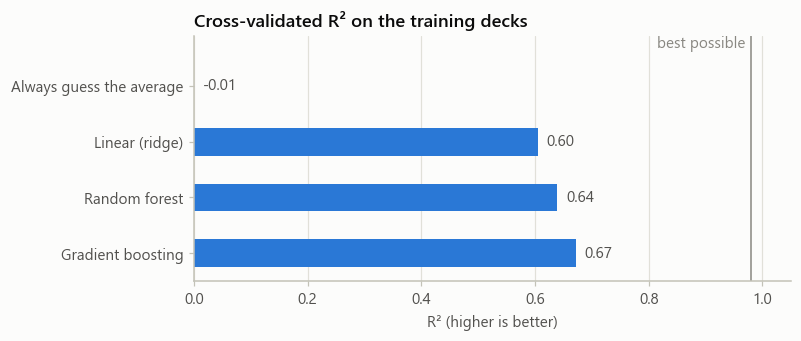

In [5]:
fig, ax = plt.subplots(figsize=(7, 2.9))
r2 = comparison["R²"]
ax.barh(r2.index, r2.clip(lower=0), color=BLUE, height=0.5)
for y, v in enumerate(r2):
    ax.text(max(v, 0) + 0.015, y, f"{v:.2f}", va="center", color=INK_2)
ax.axvline(ceiling, color=MUTED, linewidth=1)
ax.text(ceiling - 0.01, -0.62, "best possible", color=MUTED, ha="right", va="bottom")
ax.set_xlim(0, 1.05)
ax.set_ylim(len(r2) - 0.5, -0.9)
ax.set_title("Cross-validated R² on the training decks")
ax.set_xlabel("R² (higher is better)")
ax.grid(axis="y", visible=False)
plt.show()

All three real models beat guessing by a wide margin. Gradient boosting is best: R² 0.67, and an MAE of 0.15, meaning it misses a deck's win rate by 15 points on average. For comparison, v1's cross-validated R² was −1.33.

The gap between 0.67 and the 0.98 ceiling is room for better features: the model only sees deck totals, not how individual cards combine.

## 4. Would more decks help?

A learning curve trains the same model on bigger and bigger slices of the training data.
The first point uses 9 decks, as many as v1 had.

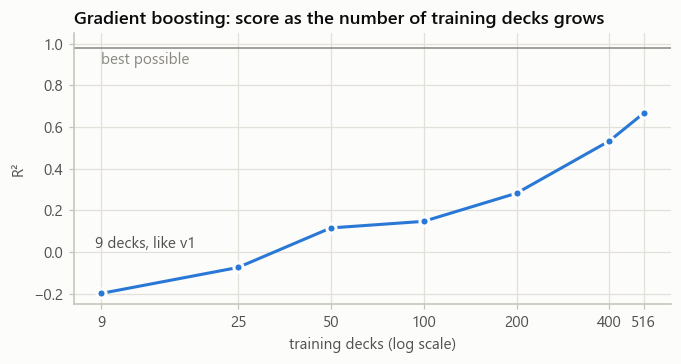

,9,25,50,100,200,400,516
cross-validated R²,-0.198,-0.074,0.116,0.147,0.282,0.533,0.666


In [6]:
best_name = comparison["R²"].idxmax()
largest = min(len(fold) for fold, _ in cv.split(X_train))  # size of a cross-validation training fold
sizes, _, valid = learning_curve(models[best_name], X_train, y_train, cv=cv, scoring="r2",
                                 train_sizes=[9, 25, 50, 100, 200, 400, largest], shuffle=True, random_state=0)
curve = pd.Series(valid.mean(axis=1), index=sizes, name="cross-validated R²")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(curve.index, curve.clip(lower=-0.2).values, color=BLUE, marker="o", markersize=6,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.axhline(ceiling, color=MUTED, linewidth=1)
ax.text(curve.index[0], ceiling - 0.02, "best possible", color=MUTED, va="top")
ax.annotate("9 decks, like v1", (curve.index[0], max(curve.iloc[0], -0.2)), xytext=(-4, 30),
            textcoords="offset points", color=INK_2)
ax.set_xscale("log")
ax.set_xticks(curve.index, [str(s) for s in curve.index])
ax.minorticks_off()
ax.set_ylim(-0.25, 1.05)
ax.set_title(f"{best_name}: score as the number of training decks grows")
ax.set_xlabel("training decks (log scale)")
ax.set_ylabel("R²")
plt.show()
curve.round(3).to_frame().T

With 9 decks the model is worse than guessing the average (R² −0.20): that was v1's situation. The score is still climbing at the largest size, so more simulated decks would probably help. That's an easy experiment: raise `N_DECKS` in notebook 01 and re-run the series.

## 5. The final exam: the test set

Now, once, we train the best model on all training decks and score it on the test decks it has never seen.

Gradient boosting: test R² 0.691, test MAE 0.148 on 154 unseen decks


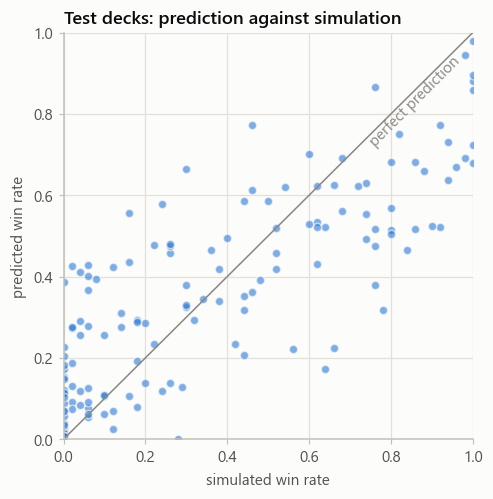

In [7]:
model = clone(models[best_name]).fit(X_train, y_train)
pred = model.predict(X_test)
test_r2, test_mae = r2_score(y_test, pred), mean_absolute_error(y_test, pred)
print(f"{best_name}: test R² {test_r2:.3f}, test MAE {test_mae:.3f} on {len(test)} unseen decks")

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1)
ax.scatter(y_test, pred, s=30, color=BLUE, alpha=0.6, edgecolors=SURFACE, linewidths=1)
ax.text(0.97, 0.93, "perfect prediction", color=MUTED, ha="right", rotation=45, rotation_mode="anchor")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="simulated win rate", ylabel="predicted win rate")
ax.set_title("Test decks: prediction against simulation")
plt.show()

On decks it never saw, the model scores about the same as in cross-validation (R² 0.69 against 0.67), so the cross-validation estimate was honest.
Most of the error sits on the left edge: decks that never won, to which the model still gives up to 40%.

## 6. What did the model learn?

Permutation importance shuffles one feature at a time on the test set and measures how much the score drops.
A big drop means the model relies on that feature.

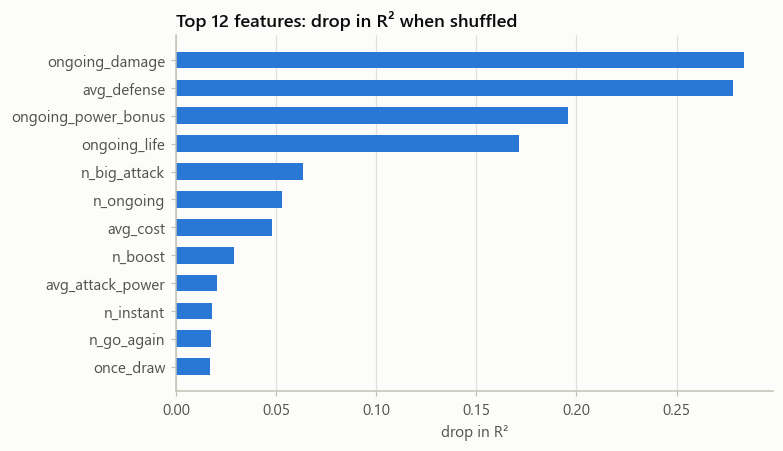

In [8]:
imp = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=0, scoring="r2")
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(12)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_title("Top 12 features: drop in R² when shuffled")
ax.set_xlabel("drop in R²")
ax.grid(axis="y", visible=False)
plt.show()

The model leans on the every-turn effects (`ongoing_damage`, `ongoing_power_bonus`, `ongoing_life`) and on `avg_defense`. In this simulator an item that deals damage or heals every turn adds up over a long game, and good blocks keep you alive while it does.

That is a statement about **the simulator**, not about Flesh and Blood. If the engine over-rewards items, the model faithfully learns that too.

## 7. Card by card: which cards help?

Another way to model the same data: one column per card, holding how many copies the deck runs.
A ridge regression on those columns gives each card a number: the change in win rate for one extra copy, compared with an average card.
This model can't say anything about a card it has never seen (the feature model can, because it reads stats), but it is easy to read.

In [9]:
deck_cards = pd.read_csv(DATA / "deck_cards.csv")
cards = pd.read_csv(DATA / "cards.csv").set_index("id")
counts = deck_cards.pivot_table(index="deck_id", columns="card_id", values="copies", fill_value=0)
counts_train = counts.loc[train.deck_id]

card_model = RidgeCV(alphas=np.logspace(-1, 3, 30))
card_cv = cross_val_score(card_model, counts_train, y_train.values, cv=cv, scoring="r2").mean()
card_model.fit(counts_train, y_train.values)
print(f"Card-count model: cross-validated R² {card_cv:.3f} (feature model: {comparison.loc[best_name, 'R²']:.3f})")

value = (pd.DataFrame({"per_copy": card_model.coef_, "decks": (counts_train > 0).sum()}, index=counts.columns)
         .join(cards[["kind", "custom", "cost", "pitch", "power", "defense"]]))
print("\nBest official cards (seen in at least 15 training decks):")
value[(~value.custom) & (value.decks >= 15)].sort_values("per_copy", ascending=False).head(8).round(3)

Card-count model: cross-validated R² 0.332 (feature model: 0.672)

Best official cards (seen in at least 15 training decks):


,per_copy,decks,kind,custom,cost,pitch,power,defense
card_id,,,,,,,,
Medkit (3),0.144,19,item,False,0,3,0,0
Teklo Pounder (3),0.095,21,item,False,2,3,0,0
Terminator Tank (1),0.056,20,attack,False,6,1,6,3
Quickfire (1),0.042,16,action,False,2,1,0,2
Evo Scatter Shot (3),0.039,15,evo,False,3,3,0,2
Maximum Velocity (1),0.038,17,attack,False,2,1,10,3
Evo Face Breaker (1),0.037,18,evo,False,0,1,0,0
Scrap Prospector (3),0.033,19,attack,False,0,3,1,3


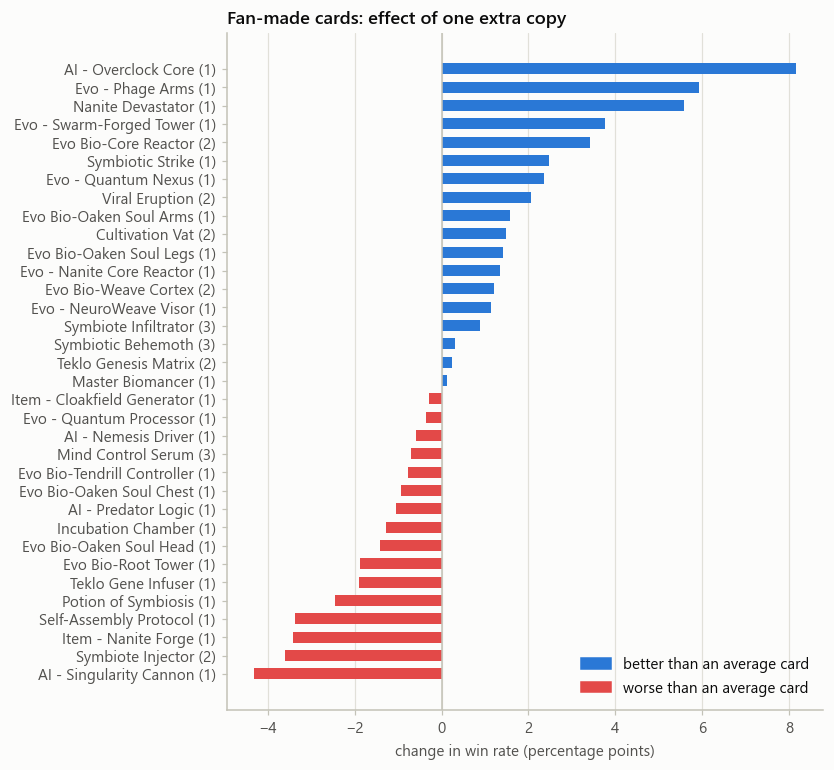

,per_copy,decks,kind,custom,cost,pitch,power,defense
card_id,,,,,,,,
AI - Overclock Core (1),0.082,27,item,True,1,1,0,0
Evo - Phage Arms (1),0.059,28,evo,True,2,1,0,3
Nanite Devastator (1),0.056,28,evo,True,4,1,7,2
Evo - Swarm-Forged Tower (1),0.038,34,evo,True,2,1,0,3
Evo Bio-Core Reactor (2),0.034,40,evo,True,2,2,0,2
Symbiotic Strike (1),0.025,56,attack,True,6,1,6,3
Evo - Quantum Nexus (1),0.023,37,evo,True,4,1,0,3
Viral Eruption (2),0.021,42,attack,True,6,2,6,3
Evo Bio-Oaken Soul Arms (1),0.016,34,evo,True,2,1,0,1


In [10]:
custom = value[value.custom].sort_values("per_copy")

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(custom.index, custom.per_copy * 100, color=[BLUE if v > 0 else RED for v in custom.per_copy], height=0.6)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_title("Fan-made cards: effect of one extra copy")
ax.set_xlabel("change in win rate (percentage points)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=BLUE, label="better than an average card"),
                   Patch(color=RED, label="worse than an average card")], loc="lower right")
plt.show()
custom.sort_values("per_copy", ascending=False).round(3)

How to read this chart:

* **AI - Overclock Core** comes out on top because it is the only fan-made card whose text the parser understood (+2 power every turn).
* **Nanite Devastator** raises the weapon from 3 to 7 power, and the Nano and Quantum Evos give 3 defense instead of the base 1. That is what lifts them.
* Cards at the bottom, such as **AI - Singularity Cannon** or **Item - Nanite Forge**, cost resources and, as far as the simulator knows, do nothing. Their real effects are in `teklostudy.md`.
* The card-count model explains only about a third of the differences between decks (R² 0.33), so short bars are within noise. Read the ends of the chart, not the middle.

So this is not yet a verdict on the fan-made designs. Notebook 04 lets an LLM read their real rules text, re-simulates, and redraws this chart.

## 8. Save the model

In [11]:
MODELS = ROOT / "models" / "v2"
MODELS.mkdir(parents=True, exist_ok=True)
joblib.dump(model, MODELS / "model.joblib")
info = {
    "model": best_name,
    "estimator": type(model).__name__,
    "target": "win_rate",
    "features": FEATURES,
    "metrics": {
        "cv_r2": round(float(comparison.loc[best_name, "R²"]), 4),
        "cv_r2_std": round(float(comparison.loc[best_name, "R² std"]), 4),
        "cv_mae": round(float(comparison.loc[best_name, "MAE"]), 4),
        "test_r2": round(float(test_r2), 4),
        "test_mae": round(float(test_mae), 4),
        "best_possible_r2": round(float(ceiling), 4),
    },
    "data": {"train_decks": len(train), "test_decks": len(test), "games_per_deck": int(data.games.iloc[0])},
    "sklearn_version": sklearn.__version__,
}
(MODELS / "model_info.json").write_text(json.dumps(info, indent=2))
info["metrics"]

{'cv_r2': 0.6719,
 'cv_r2_std': 0.0206,
 'cv_mae': 0.1474,
 'test_r2': 0.6909,
 'test_mae': 0.1482,
 'best_possible_r2': 0.9802}

## 9. Use it on a brand-new deck

The model takes a table with **named columns**, built by `teklo.deck_features`.
(v1's model card asked for a bare list of 19 numbers while the model expected 17, which is why its Quick Start crashed.)
To check the prediction, we also simulate the deck for 200 games.

In [12]:
all_cards = teklo.load_cards(ROOT / "notebooks" / "card.csv", ROOT / "custom_cards.csv")
opponent = teklo.reference_opponent(teklo.generic_pool(all_cards))
new_deck = teklo.random_deck(teklo.teklo_pool(all_cards), np.random.default_rng(999))

x = pd.DataFrame([teklo.deck_features(new_deck)])[FEATURES]
predicted = model.predict(x)[0]
simulated = teklo.evaluate_deck(new_deck, opponent, n_games=200, seed=999)["win_rate"]
print(f"predicted win rate: {predicted:.0%}   simulated over 200 games: {simulated:.0%}")
pd.Series(teklo.deck_counts(new_deck), name="copies").rename_axis("card").reset_index()

predicted win rate: 5%   simulated over 200 games: 2%


,card,copies
0,Gas Guzzler (3),3
1,Dumpster Dive (2),3
2,Snatch (1),3
3,Dive Through Data (1),2
4,Life of the Party (3),1
5,Scramble Pulse (3),3
6,Jump Start (2),3
7,Bingo (1),3
8,Spring a Leak (2),3
9,Evo Mach Breaker (1),3


Next: **04 · LLMs with Hugging Face Inference Providers** (needs a Hugging Face token).